# Does SLC38A4 loss drive fetal reprogramming, or loss of mature hepatocyte identity?
##### Author: Inês Cebola (Imperial College London)

If SLC38A4 knockout dedifferentiated hepatocytes toward a **fetal** state, an unbiased
fetal-vs-adult hepatocyte signature should shift **toward the fetal/immature pole** in KO cells:
immature markers up, adult markers down.

We test this directly using an independent human liver developmental cell atlas
(**Wesley et al., liver development atlas; PMC7617064**), which defines stage-specific
marker genes along the hepatocyte trajectory:

`Hepatoblast (HB1/HB2) → Fetal hepatocyte (FH1/FH2) → Adult hepatocyte (AH)`

Three signatures were extracted from the atlas Figure-1 hepatocyte stage-specific DEG table
(saved in `reference/`): **Hepatoblast_HB** (most immature), **Fetal_hepatocyte_FH**, and
**Adult_hepatocyte_AH** (most mature). We score them in the SLC38A4-KO Huh7.5 RNA-seq using
(1) the stage gradient of mean KO log2FC, (2) pre-ranked GSEA on the KO-vs-WT *t*-statistic, and
(3) a per-sample z-scored module score.

> **Framing = "show both, decide later".** The notebook reports the result whichever way it falls.
> **Caveats:** Huh7.5 is a hepatoma line (already partly dedifferentiated), so it is a conservative
> substrate for a developmental-identity test; and the atlas "FH" set is rich in hepatocyte-function
> genes, so its behaviour partly reflects general hepatocyte identity.
>
> **Patient cohorts (ISAIAH, InTeam) are not scored here** — the mounted ISAIAH object contains only
> SLC38A4 CLR counts + MELD (no gene matrix), and the InTeam results file was not retrievable in this
> environment. Add them by pointing the `PATIENT_MATRIX` cell at a full genes-x-samples matrix.


## 1. Setup, load KO data and atlas signatures

In [1]:
import os, numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
import gseapy as gp

mpl.rcParams.update({"figure.dpi":120,"savefig.dpi":300,"savefig.bbox":"tight","font.size":8,
                     "axes.titlesize":9,"pdf.fonttype":42,"ps.fonttype":42,"axes.spines.top":False,"axes.spines.right":False,
                     "font.family":"sans-serif","font.sans-serif":["Helvetica","Arial","Liberation Sans","DejaVu Sans"],
                     "axes.unicode_minus":False})
REF="reference"

# NOTE (2026-08-14): originally pointed at SLC38A4_KO_RNA-seq/limma_KO_vs_WT_combined.csv /
# voom_logCPM.csv / sample_metadata.csv -- the pre-mincount10-filter differential-expression
# result (10,597 genes). Repointed to the current mincount10 files already used by every other
# notebook in this repo (14,113 genes) so this analysis is run on the same DE result cited
# elsewhere (Fig. 3D/3C, Fig. S8B), not a stale predecessor. Confirmed identical sample set/order.
de=pd.read_csv("Fig3C_limma_KO_vs_WT_combined_mincount10.csv", index_col=0).dropna(subset=["gene_symbol"]).drop_duplicates("gene_symbol")
voom=pd.read_csv("Fig3B_voom_logCPM_mincount10.csv", index_col=0)
meta=pd.read_csv("sample_metadata_mincount10.csv", index_col=0)
samples=meta.index.tolist()
expr=voom.set_index("gene_symbol")[samples]; expr=expr[~expr.index.duplicated()]

# signatures (GMT saved from the atlas)
sig={}
for line in open(f"{REF}/liver_developmental_signatures.gmt"):
    p=line.rstrip("\n").split("\t"); sig[p[0]]=p[2:]
print("Signatures:", {k:len(v) for k,v in sig.items()})
print("KO genes:", de.shape[0], "| voom samples:", len(samples))


Signatures: {'Adult_hepatocyte_AH': 99, 'Fetal_hepatocyte_FH': 151, 'Hepatoblast_HB': 174}
KO genes: 14108 | voom samples: 18


## 2. Stage gradient — mean KO(vs WT) log2FC along the developmental trajectory
Dedifferentiation predicts immature (HB/FH) **up** and adult (AH) **down**. A flat/declining profile with no fetal-ward rise argues against fetal reprogramming.

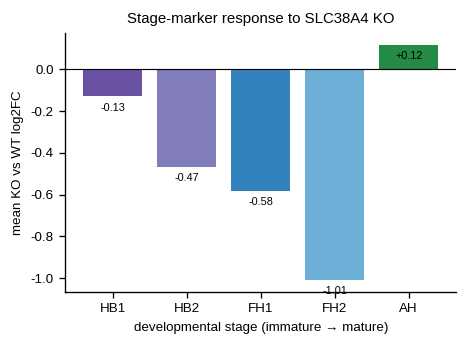

stage means: {'HB1': np.float64(-0.129), 'HB2': np.float64(-0.468), 'FH1': np.float64(-0.584), 'FH2': np.float64(-1.009), 'AH': np.float64(0.118)}


In [2]:
# rebuild the five individual stage marker sets straight from the atlas file
atlas=pd.read_excel(f"{REF}/PMC7617064_liver_atlas_Fig1_hepatocyte_DEG.xlsx",
                    sheet_name="Hepatocyte_stage-specific DEG", header=None)
hdr=atlas.iloc[5].tolist(); stage_sets={}
for c,h in enumerate(hdr):
    if isinstance(h,str) and h.endswith("_names"):
        s=h.replace("_names",""); stage_sets[s]=atlas.iloc[6:,c].dropna().astype(str).tolist()
lfc=de.set_index("gene_symbol")["logFC"]
order=["HB1","HB2","FH1","FH2","AH"]
means=[lfc.reindex([g for g in stage_sets[s] if g in lfc.index]).mean() for s in order]

fig,ax=plt.subplots(figsize=(4.2,2.8))
colors=["#6a51a3","#807dba","#3182bd","#6baed6","#238b45"]
ax.bar(order, means, color=colors)
ax.axhline(0,color="black",lw=0.7); ax.set_ylabel("mean KO vs WT log2FC")
ax.set_xlabel("developmental stage (immature → mature)")
ax.set_title("Stage-marker response to SLC38A4 KO")
for i,m in enumerate(means): ax.text(i, m-0.03, f"{m:+.2f}", ha="center", va="top", fontsize=6.5)
fig.savefig("DevSig_A_stage_gradient.pdf"); plt.show()
print("stage means:", dict(zip(order,[round(m,3) for m in means])))


## 3. Pre-ranked GSEA on the KO-vs-WT contrast
Genes ranked by limma *t*-statistic (KO vs WT). Negative NES = signature enriched among genes **down** in KO.

2026-08-14 14:33:48,021 [WARNING] Duplicated values found in preranked stats: 0.02% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


                        NES  NOM p-val  FDR q-val
Term                                             
Hepatoblast_HB      -1.5924     0.0017     0.0061
Fetal_hepatocyte_FH -1.7052     0.0000     0.0017
Adult_hepatocyte_AH -1.1194     0.2781     0.2455


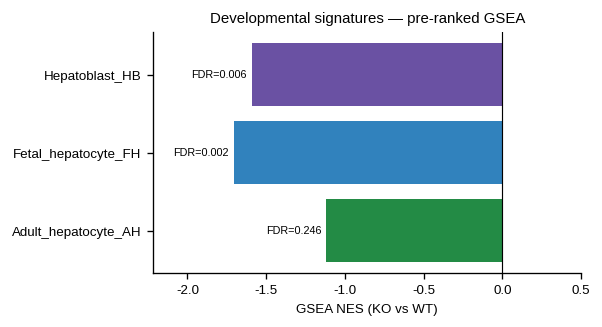

In [3]:
rnk=de[["gene_symbol","t"]].sort_values("t",ascending=False)
pre=gp.prerank(rnk=rnk, gene_sets=sig, permutation_num=1000, min_size=5, max_size=1000,
               seed=42, threads=4, outdir=None, no_plot=True)
res=pre.res2d.copy()
for c in ["NES","NOM p-val","FDR q-val"]: res[c]=pd.to_numeric(res[c],errors="coerce")
res=res.set_index("Term").loc[["Hepatoblast_HB","Fetal_hepatocyte_FH","Adult_hepatocyte_AH"]]
print(res[["NES","NOM p-val","FDR q-val"]].round(4).to_string())

fig,ax=plt.subplots(figsize=(4.6,2.6))
y=np.arange(len(res))[::-1]
bars=ax.barh(y, res["NES"], color=["#6a51a3","#3182bd","#238b45"])
ax.set_yticks(y); ax.set_yticklabels(res.index)
ax.axvline(0,color="black",lw=0.7); ax.set_xlabel("GSEA NES (KO vs WT)")
ax.set_title("Developmental signatures — pre-ranked GSEA")
for yi,(nes,fdr) in zip(y, res[["NES","FDR q-val"]].values):
    ax.text(nes-0.03 if nes<0 else nes+0.03, yi, f"FDR={fdr:.3f}",
            va="center", ha="right" if nes<0 else "left", fontsize=6.5)
ax.set_xlim(min(res['NES'].min()*1.3,-2), 0.5)
fig.savefig("DevSig_B_GSEA_NES.pdf"); plt.show()


## 4. Per-sample module score (z-scored) — KO vs WT
Gene-wise z-score across the 18 samples, averaged within each signature (Seurat-style module score). Shows the *relative* shift per sample; tested with Mann–Whitney U.

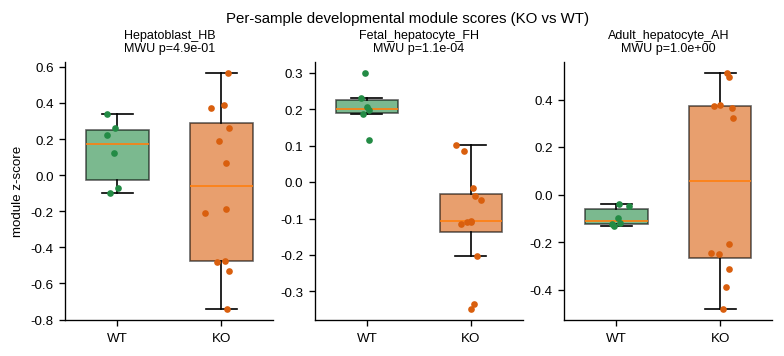

saved figures + DevSig_module_scores.csv + DevSig_GSEA_results.csv


In [4]:
z=expr.sub(expr.mean(1),axis=0).div(expr.std(1).replace(0,np.nan),axis=0)
score={}
for name,genes in sig.items():
    g=[x for x in genes if x in z.index]
    score[name]=z.loc[g].mean(0)
S=pd.DataFrame(score); S["cond"]=meta.loc[S.index,"condition"].values

fig,axes=plt.subplots(1,3,figsize=(7.6,2.8))
for ax,name in zip(axes, ["Hepatoblast_HB","Fetal_hepatocyte_FH","Adult_hepatocyte_AH"]):
    ko=S.loc[S.cond=="KO",name]; wt=S.loc[S.cond=="WT",name]
    parts=ax.boxplot([wt,ko], labels=["WT","KO"], widths=0.6, patch_artist=True, showfliers=False)
    for patch,c in zip(parts['boxes'], ["#238b45","#d95f0e"]): patch.set_facecolor(c); patch.set_alpha(.6)
    for i,(vals,c) in enumerate(zip([wt,ko],["#238b45","#d95f0e"]),start=1):
        ax.scatter(np.random.normal(i,0.05,len(vals)), vals, s=9, color=c, zorder=3)
    U,p=mannwhitneyu(ko,wt)
    ax.set_title(f"{name}\nMWU p={p:.1e}", fontsize=7.5)
    ax.set_ylabel("module z-score" if name.startswith("Hepatoblast") else "")
fig.suptitle("Per-sample developmental module scores (KO vs WT)", y=1.03, fontsize=9)
fig.savefig("DevSig_C_module_scores.pdf"); plt.show()

# export scores + GSEA table
S.to_csv("DevSig_module_scores.csv")
res.reset_index().to_csv("DevSig_GSEA_results.csv", index=False)
print("saved figures + DevSig_module_scores.csv + DevSig_GSEA_results.csv")


## 5. Interpretation (auto-summary)

In [5]:
verdict=[]
nes=res["NES"]
if (nes<0).all():
    verdict.append("All three hepatocyte-developmental signatures are DOWN in KO (negative NES).")
if nes["Fetal_hepatocyte_FH"]<nes["Adult_hepatocyte_AH"] and nes["Hepatoblast_HB"]<nes["Adult_hepatocyte_AH"]:
    verdict.append("The immature (fetal/hepatoblast) programmes are MORE suppressed than the adult one "
                   "-> the opposite of a fetal-ward shift.")
verdict.append("Conclusion: the data support LOSS OF HEPATOCYTE-LINEAGE IDENTITY, not fetal reprogramming. "
               "AFP and the HNF4a-P2 isoform remain valid as narrow, specific features.")
print("\n".join("- "+v for v in verdict))


- All three hepatocyte-developmental signatures are DOWN in KO (negative NES).
- The immature (fetal/hepatoblast) programmes are MORE suppressed than the adult one -> the opposite of a fetal-ward shift.
- Conclusion: the data support LOSS OF HEPATOCYTE-LINEAGE IDENTITY, not fetal reprogramming. AFP and the HNF4a-P2 isoform remain valid as narrow, specific features.
